In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

# Load the cleaned Superstore dataset
df = pd.read_csv("../data/processed/superstore_cleaned.csv")

# Display the first five rows
df.head()

,row_id,order_id,order_date,ship_date,ship_mode,customer_id,customer_name,segment,country_region,city,...,postal_code,region,product_id,category,sub_category,product_name,sales,quantity,discount,profit
0,1,US-2023-103800,2023-01-03,2023-01-07,Standard Class,DP-13000,Darren Powers,Consumer,United States,Houston,...,77095,Central,OFF-PA-10000174,Office Supplies,Paper,"Message Book, Wirebound, Four 5 1/2"" X 4"" Form...",16.448,2,0.2,5.5512
1,2,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-BI-10004094,Office Supplies,Binders,GBC Standard Plastic Binding Systems Combs,3.540,2,0.8,-5.4870
2,3,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-LA-10003223,Office Supplies,Labels,Avery 508,11.784,3,0.2,4.2717
3,4,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-ST-10002743,Office Supplies,Storage,SAFCO Boltless Steel Shelving,272.736,3,0.2,-64.7748
4,5,US-2023-141817,2023-01-05,2023-01-12,Standard Class,MB-18085,Mick Brown,Consumer,United States,Philadelphia,...,19143,East,OFF-AR-10003478,Office Supplies,Art,Avery Hi-Liter EverBold Pen Style Fluorescent ...,19.536,3,0.2,4.8840


In [2]:
# Check column names, data types, and non-null values
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10194 entries, 0 to 10193
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   row_id          10194 non-null  int64  
 1   order_id        10194 non-null  object 
 2   order_date      10194 non-null  object 
 3   ship_date       10194 non-null  object 
 4   ship_mode       10194 non-null  object 
 5   customer_id     10194 non-null  object 
 6   customer_name   10194 non-null  object 
 7   segment         10194 non-null  object 
 8   country_region  10194 non-null  object 
 9   city            10194 non-null  object 
 10  state_province  10194 non-null  object 
 11  postal_code     10194 non-null  object 
 12  region          10194 non-null  object 
 13  product_id      10194 non-null  object 
 14  category        10194 non-null  object 
 15  sub_category    10194 non-null  object 
 16  product_name    10194 non-null  object 
 17  sales           10194 non-null 

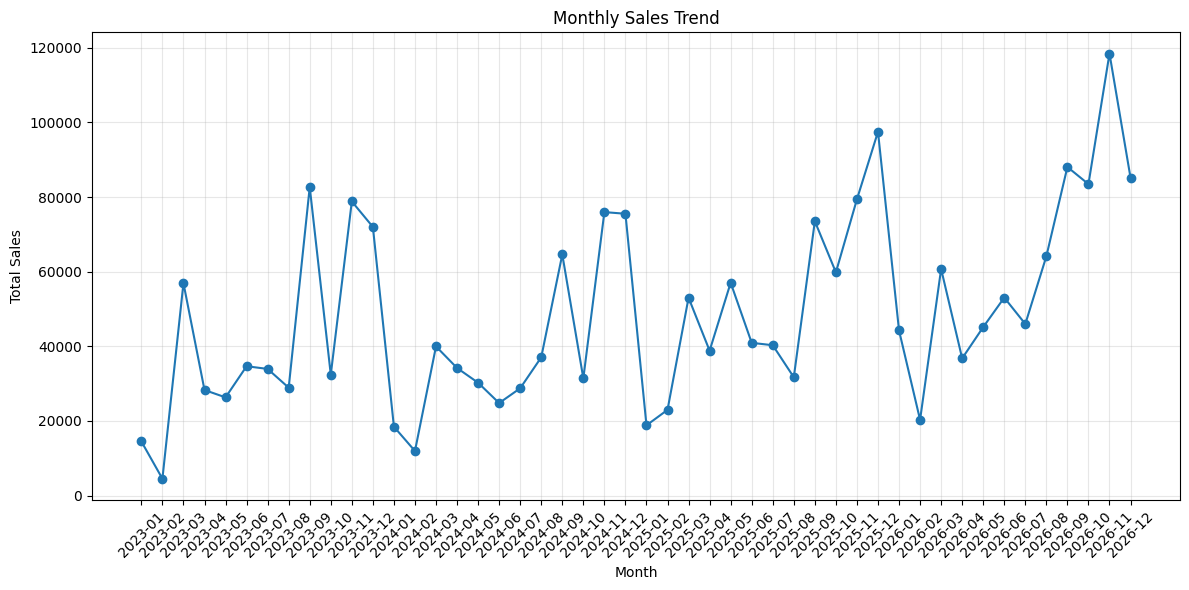

In [3]:
# Convert order_date to datetime
df["order_date"] = pd.to_datetime(df["order_date"])

# Calculate monthly sales
monthly_sales = (
    df.groupby(df["order_date"].dt.to_period("M"))["sales"]
    .sum()
)

# Plot the monthly sales trend
plt.figure(figsize=(12, 6))
plt.plot(monthly_sales.index.astype(str), monthly_sales.values, marker="o")
plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Finding 1: Monthly Sales Trend

* Monthly sales fluctuate considerably over time.
* The highest visible peak occurs around October 2026, at approximately 118,000.
* These trends can help identify high- and low-performing months for sales planning.


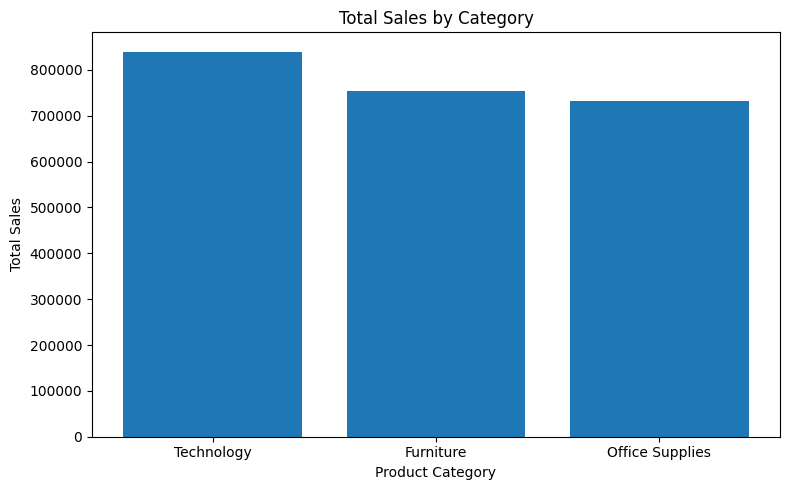

In [4]:
# Calculate total sales by product category
category_sales = df.groupby("category")["sales"].sum().sort_values(ascending=False)

# Create the bar chart
plt.figure(figsize=(8, 5))
plt.bar(category_sales.index, category_sales.values)
plt.title("Total Sales by Category")
plt.xlabel("Product Category")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.show()

### Finding 2: Sales by Product Category

* The bar chart compares total sales across product categories.
* It helps identify which category contributes the most and the least to total sales.


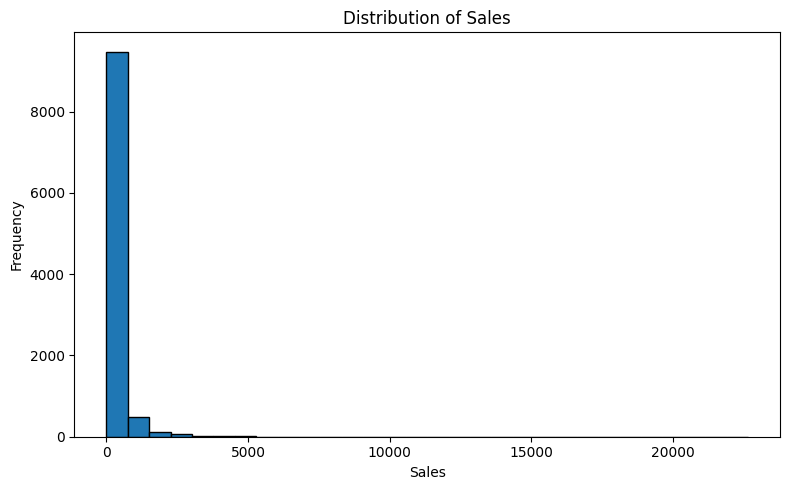

In [5]:
# Distribution of sales values
plt.figure(figsize=(8, 5))
plt.hist(df["sales"], bins=30, edgecolor="black")
plt.title("Distribution of Sales")
plt.xlabel("Sales")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

### Finding 3: Distribution of Sales

* The histogram shows how frequently different sales amounts occur.
* It helps identify the common sales ranges and the spread of sales values.

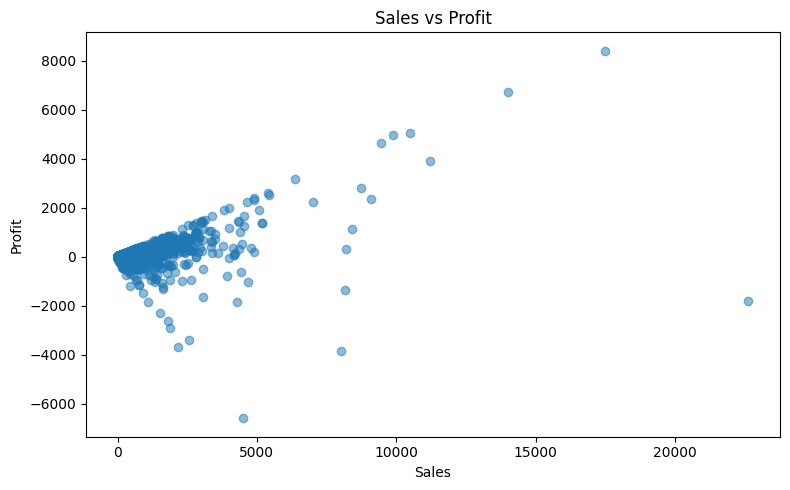

In [6]:
# Relationship between sales and profit
plt.figure(figsize=(8, 5))
plt.scatter(df["sales"], df["profit"], alpha=0.5)
plt.title("Sales vs Profit")
plt.xlabel("Sales")
plt.ylabel("Profit")
plt.tight_layout()
plt.show()

### Finding 4: Sales vs Profit

* The scatter plot shows the relationship between sales and profit.
* It helps identify transactions with positive and negative profit.


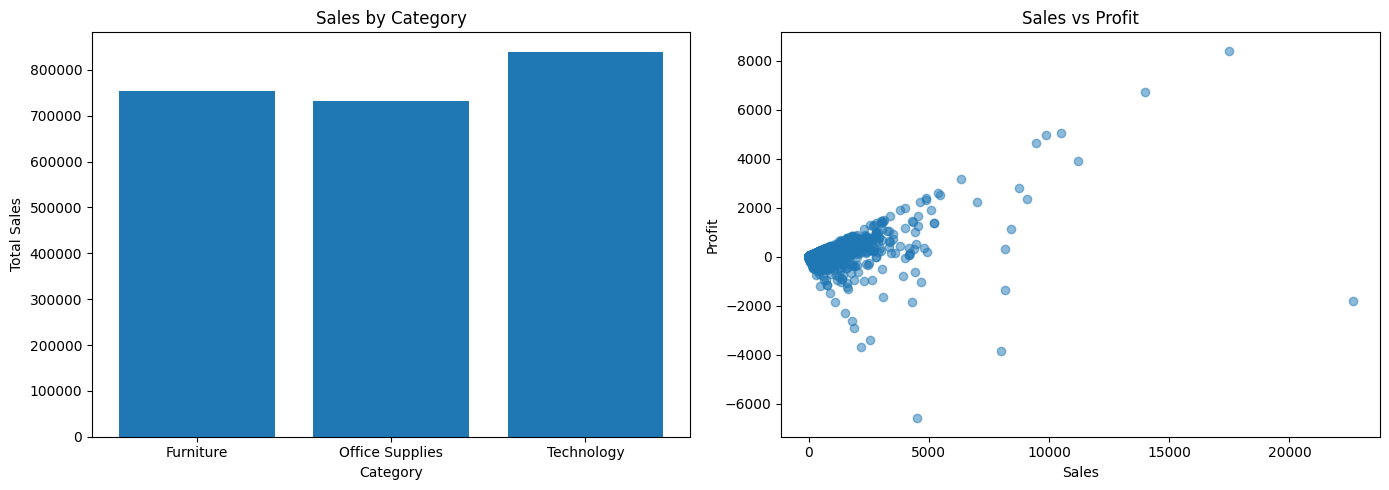

In [7]:
# Create multiple charts together using subplots
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Bar chart: Sales by category
category_sales = df.groupby("category")["sales"].sum()
axes[0].bar(category_sales.index, category_sales.values)
axes[0].set_title("Sales by Category")
axes[0].set_xlabel("Category")
axes[0].set_ylabel("Total Sales")

# Scatter plot: Sales vs Profit
axes[1].scatter(df["sales"], df["profit"], alpha=0.5)
axes[1].set_title("Sales vs Profit")
axes[1].set_xlabel("Sales")
axes[1].set_ylabel("Profit")

plt.tight_layout()
plt.show()

### Finding 5: Multiple Charts Using Subplots

* The subplots display sales by category and the relationship between sales and profit side by side.
* This allows both visualizations to be compared within a single figure.


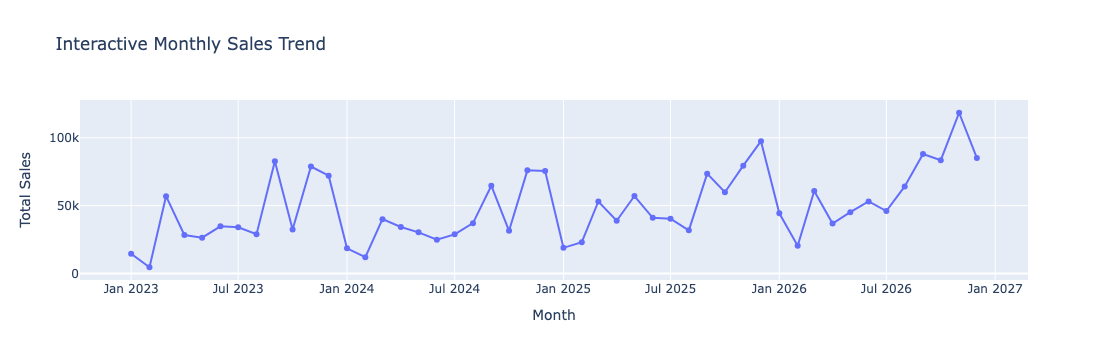

In [8]:
# Interactive monthly sales trend using Plotly
monthly_sales_df = monthly_sales.reset_index()
monthly_sales_df.columns = ["month", "sales"]
monthly_sales_df["month"] = monthly_sales_df["month"].astype(str)

fig = px.line(
    monthly_sales_df,
    x="month",
    y="sales",
    title="Interactive Monthly Sales Trend",
    markers=True
)

fig.update_layout(
    xaxis_title="Month",
    yaxis_title="Total Sales"
)

fig.show()

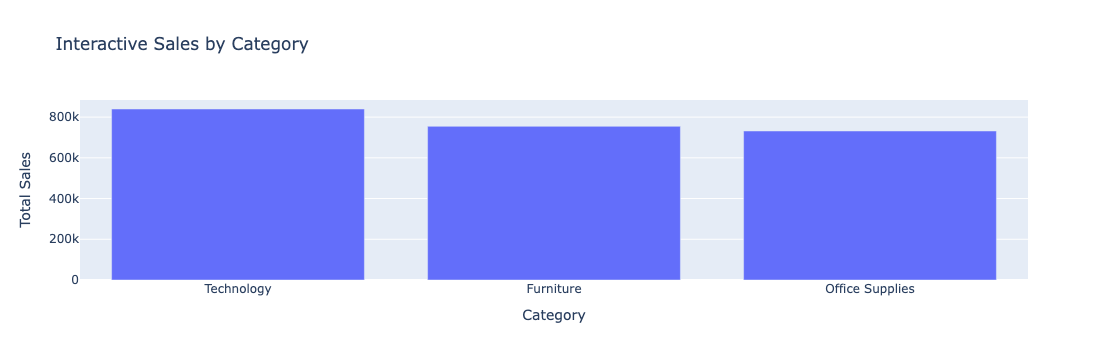

In [9]:
# Interactive bar chart: Sales by Category
category_sales_df = (
    df.groupby("category", as_index=False)["sales"]
    .sum()
    .sort_values("sales", ascending=False)
)

fig = px.bar(
    category_sales_df,
    x="category",
    y="sales",
    title="Interactive Sales by Category",
    labels={"category": "Category", "sales": "Total Sales"}
)

fig.show()

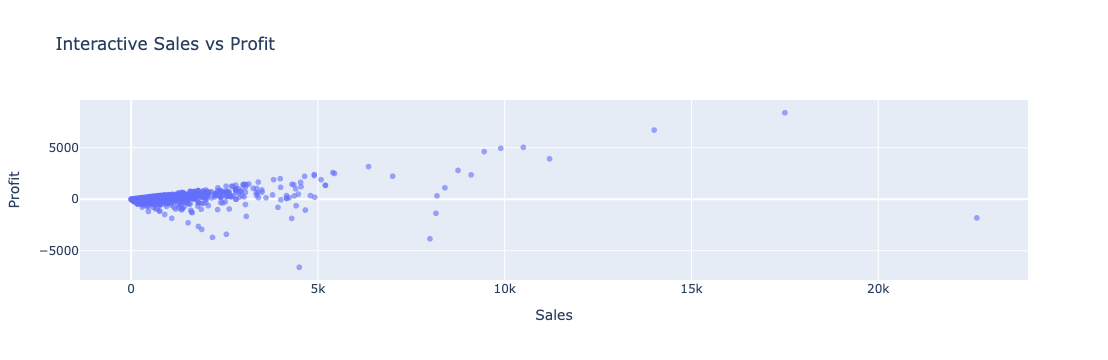

In [10]:
fig = px.scatter(
    df,
    x="sales",
    y="profit",
    title="Interactive Sales vs Profit",
    labels={"sales": "Sales", "profit": "Profit"},
    opacity=0.6
)

fig.show()

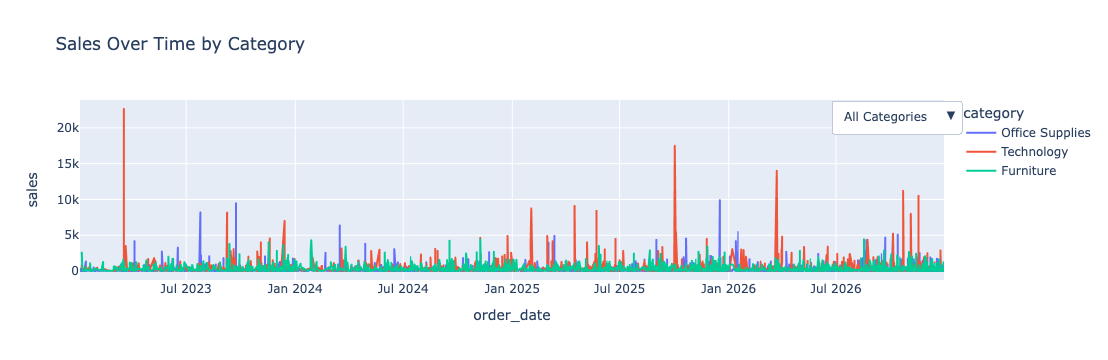

In [11]:
# Interactive sales chart with a category dropdown
fig = px.line(
    df.sort_values("order_date"),
    x="order_date",
    y="sales",
    color="category",
    title="Sales Over Time by Category"
)

fig.update_layout(
    updatemenus=[
        dict(
            buttons=[
                dict(
                    label="All Categories",
                    method="update",
                    args=[{"visible": [True, True, True]}]
                ),
                dict(
                    label="Furniture",
                    method="update",
                    args=[{"visible": [True, False, False]}]
                ),
                dict(
                    label="Office Supplies",
                    method="update",
                    args=[{"visible": [False, True, False]}]
                ),
                dict(
                    label="Technology",
                    method="update",
                    args=[{"visible": [False, False, True]}]
                )
            ],
            direction="down",
            x=1.02,
            y=1
        )
    ]
)

fig.show()

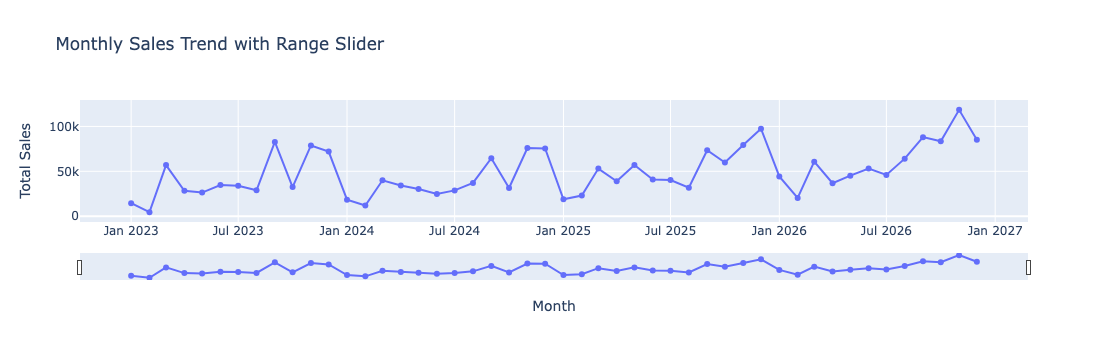

In [12]:
# Interactive monthly sales trend with a date range slider
fig = px.line(
    monthly_sales_df,
    x="month",
    y="sales",
    title="Monthly Sales Trend with Range Slider",
    markers=True
)

fig.update_xaxes(rangeslider_visible=True)

fig.update_layout(
    xaxis_title="Month",
    yaxis_title="Total Sales"
)

fig.show()

In [13]:
# Save the interactive monthly sales chart as an HTML file
fig.write_html("../reports/monthly_sales_trend.html")

print("Interactive chart saved successfully!")

Interactive chart saved successfully!


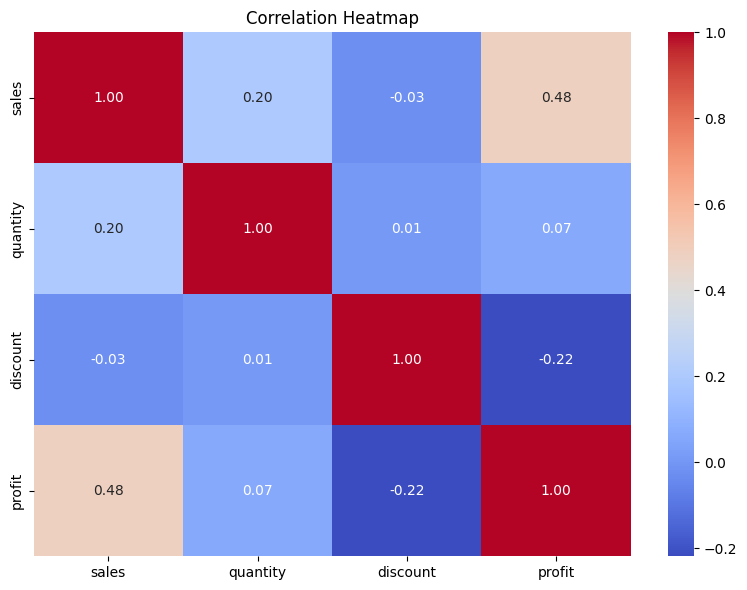

In [14]:

# Correlation matrix for numerical columns
numerical_df = df[["sales", "quantity", "discount", "profit"]]
correlation_matrix = numerical_df.corr()

# Create the correlation heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

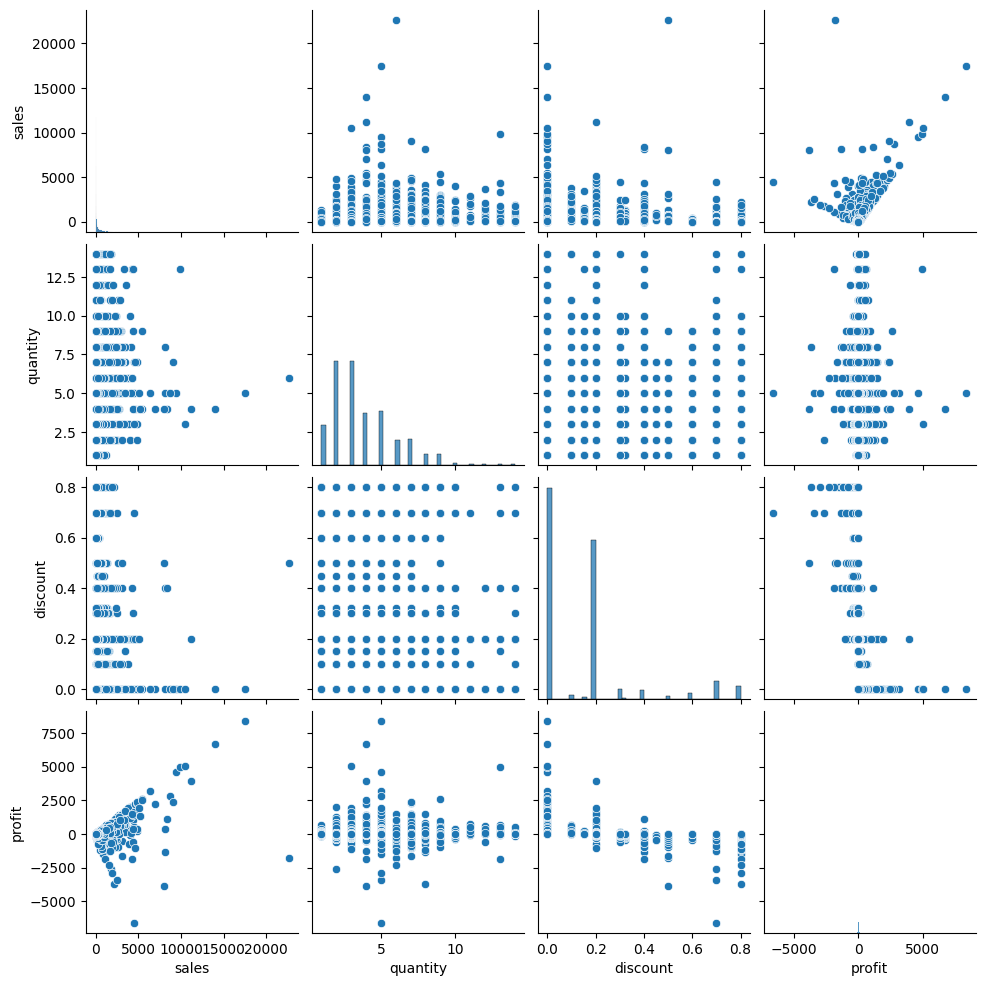

In [15]:
# Pairplot to visualize relationships between numerical variables
sns.pairplot(
    df[["sales", "quantity", "discount", "profit"]]
)

plt.show()

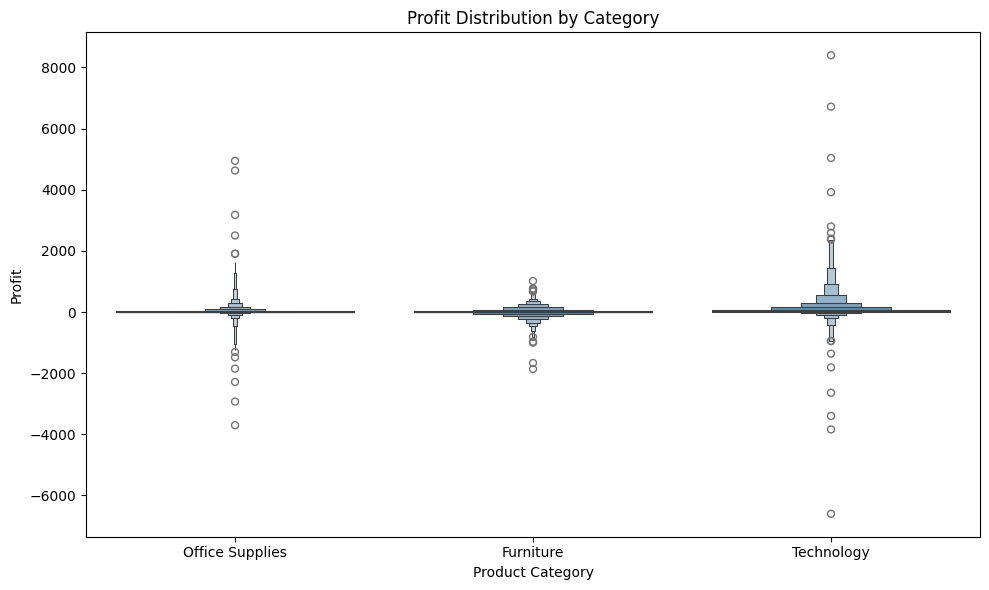

In [16]:
# Boxen plot showing profit distribution by product category
plt.figure(figsize=(10, 6))

sns.boxenplot(
    data=df,
    x="category",
    y="profit"
)

plt.title("Profit Distribution by Category")
plt.xlabel("Product Category")
plt.ylabel("Profit")
plt.tight_layout()
plt.show()

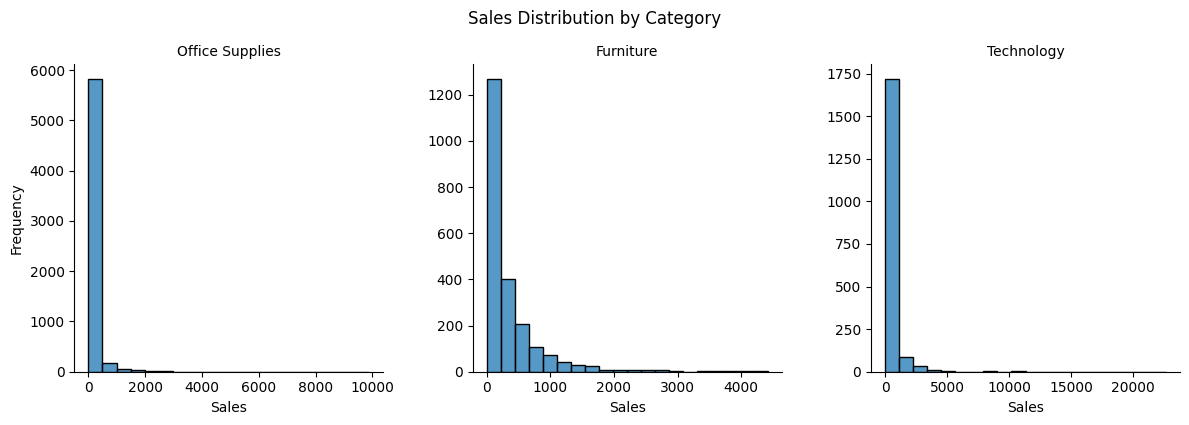

In [17]:
# FacetGrid showing sales distribution for each product category
facet_grid = sns.FacetGrid(
    df,
    col="category",
    height=4,
    sharex=False,
    sharey=False
)

facet_grid.map_dataframe(
    sns.histplot,
    x="sales",
    bins=20
)

facet_grid.set_axis_labels("Sales", "Frequency")
facet_grid.set_titles("{col_name}")
facet_grid.fig.suptitle(
    "Sales Distribution by Category",
    y=1.05
)

plt.show()